<a href="https://colab.research.google.com/github/wadeea23/Bahraini-Currency-Recognition/blob/main/wadeea_lab_money.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install roboflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 38.5 MB/s  0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.3
    Uninstalling typer-0.27.3:
      Successfully uninstalled typer-0.27.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [roboflow]


In [ ]:
!pip install roboflow ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 14.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]


In [ ]:
from ultralytics import YOLO

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [ ]:
from roboflow import Roboflow
rf = Roboflow(api_key="###")
project = rf.workspace("wadia-almutaweaa").project("bahraini_currency_recognition_w")
version = project.version(3)
dataset = version.download("yolo26")



loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Bahraini_Currency_Recognition_w-3 in yolo26:: 100%|██████████| 2427/2427 [00:00<00:00, 2999.77it/s]


In [ ]:
model = YOLO("yolo26s.pt")

In [ ]:
results = model("/content/Bahraini_Currency_Recognition_w-3/train/images/-_1_jpg.rf.148c4cd91546d8e3f1d807bf78fdd753.jpg")


image 1/1 /content/Bahraini_Currency_Recognition_w-3/train/images/-_1_jpg.rf.148c4cd91546d8e3f1d807bf78fdd753.jpg: 640x640 1 clock, 23.8ms
Speed: 70.6ms preprocess, 23.8ms inference, 25.8ms postprocess per image at shape (1, 3, 640, 640)


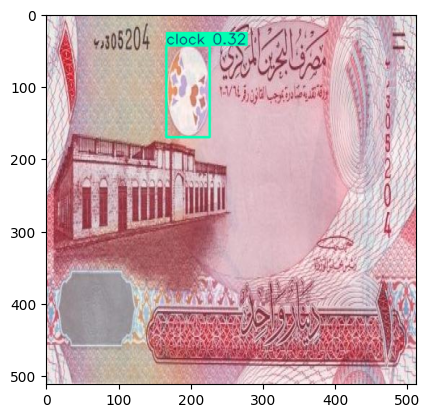

In [ ]:
import matplotlib.pyplot as plt
plt.imshow(results[0].plot()[..., ::-1]);

In [ ]:
model.train(data='/content/Bahraini_Currency_Recognition_w-3/data.yaml', epochs=5)

Ultralytics 8.4.198 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Bahraini_Currency_Recognition_w-3/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-2, nbs=64, nms=None, opset=None,

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7fa4702e8170>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043

In [ ]:
finetuned_model = YOLO('/content/runs/detect/train-2/weights/best.pt')

In [ ]:
results = finetuned_model("/content/Bahraini_Currency_Recognition_w-3/train/images/-_1_jpg.rf.148c4cd91546d8e3f1d807bf78fdd753.jpg")


image 1/1 /content/Bahraini_Currency_Recognition_w-3/train/images/-_1_jpg.rf.148c4cd91546d8e3f1d807bf78fdd753.jpg: 640x640 1 1 BHD, 23.7ms
Speed: 3.0ms preprocess, 23.7ms inference, 2.2ms postprocess per image at shape (1, 3, 640, 640)


In [ ]:
import matplotlib.pyplot as plt

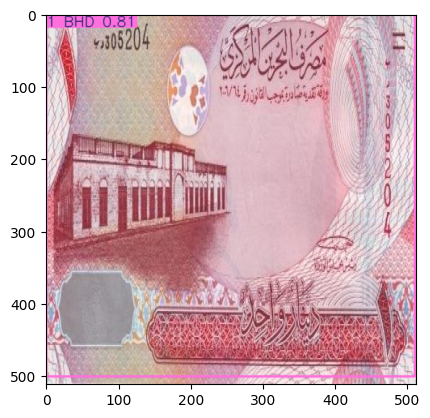

In [ ]:
plt.imshow(results[0].plot()[..., ::-1]);